# United States: Beveridge curve

Job openings rate against the unemployment rate since December 2000. Outward shifts indicate lower matching efficiency; movements along the curve reflect the cycle.

**Datasets:** `bls/jolts`, `bls/headline_monthly`

This notebook reads the latest vintage each time it runs; re-run after a new release to update every table and chart.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from labobs.load import load, vintage, curated, raw_payload
from labobs.nb import select, pivot, latest, plot_lines, plot_bars, to_annual, FOCUS, FOCUS_NAMES
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
DATASETS = ["bls/jolts", "bls/headline_monthly"]
for k in DATASETS:
    v = vintage(k)
    print(f"{k:50} vintage {v.get('vintage', 'not yet ingested'):12} sha {v.get('sha256', '')[:12]}")

bls/jolts                                          vintage not yet ingested sha 
bls/headline_monthly                               vintage not yet ingested sha 


In [3]:
jo = pivot(select(load("bls/jolts"), indicator="JTS000000000000000JOR"), columns="indicator")
ur = pivot(select(load("bls/headline_monthly"), indicator="LNS14000000"), columns="indicator")
bc = jo.join(ur, how="inner").dropna()
bc.columns = ["openings_rate", "unemployment_rate"]
bc.tail()

FileNotFoundError: bls/jolts: no processed data yet (/home/runner/work/Labour-Market-Policy/Labour-Market-Policy/data/vacancies/bls/jolts/latest.csv). Run `labobs ingest --source bls --dataset jolts` or wait for the daily run.

NameError: name 'bc' is not defined

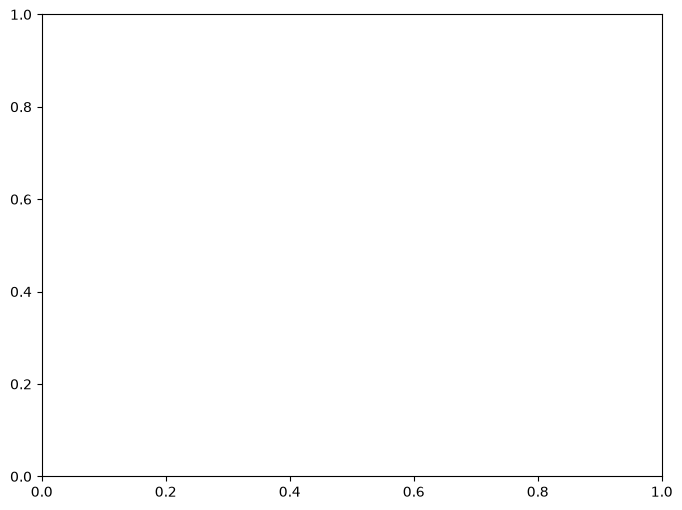

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
years = bc.index.str[:4].astype(int)
sc = ax.scatter(bc.unemployment_rate, bc.openings_rate, c=years, cmap="viridis", s=14)
ax.plot(bc.unemployment_rate, bc.openings_rate, color="#999", linewidth=0.4)
ax.annotate(bc.index[-1], (bc.unemployment_rate.iloc[-1], bc.openings_rate.iloc[-1]))
ax.set_xlabel("Unemployment rate, %"); ax.set_ylabel("Job openings rate, %")
ax.set_title("US Beveridge curve", loc="left", fontweight="bold")
fig.colorbar(sc, label="year"); fig.text(0.01, -0.02, "Source: BLS JOLTS and CPS", fontsize=8);

## Vacancies per unemployed person

In [5]:
h = load("bls/headline_monthly")
open_lvl = pivot(select(load("bls/jolts"), indicator="JTS000000000000000JOL"), columns="indicator").iloc[:, 0]
unemp = None  # unemployment level (LNS13000000) can be added to bls/headline_monthly to compute V/U directly
open_lvl.tail(12)

FileNotFoundError: bls/headline_monthly: no processed data yet (/home/runner/work/Labour-Market-Policy/Labour-Market-Policy/data/employment/bls/headline_monthly/latest.csv). Run `labobs ingest --source bls --dataset headline_monthly` or wait for the daily run.

## Curator notes

_Written by the curator after each new vintage: what changed, which revisions matter, and what to watch. See `DATA_CHANGELOG.md` for the full log._